# Gradient boosting: each tree fixes the last one's errors

You will build boosting by hand on the eight greenhouse weeks, then train scikit-learn's `GradientBoostingRegressor` on 360 seeded greenhouse rows and find where to stop adding trees.

About 10 minutes. Run the cells from top to bottom (Runtime > Run all works too). No account or key is needed.

## 1. The eight weeks

The same log as in the lesson: light hours per day, mean temperature, watering, and the harvest in kg the next week. The first forecast is the average harvest for every week.

**Look for:** the mean is `42.0`, and the residuals (harvest minus guess) start with `-13.0, -4.0, -12.0`. Their squared error is `644.0`.

In [1]:
import numpy as np

FEATURES = ["light", "temp", "water"]
# week: light hours per day, mean temperature C, watering litres per bed per day -> harvest kg the next week
weeks = np.array([[9, 18, 4], [10, 22, 5], [11, 19, 4], [12, 23, 5], [13, 18, 6], [14, 24, 5], [13, 22, 4], [9, 23, 6]], float)
harvest = np.array([29, 38, 30, 51, 44, 53, 52, 39], float)

print("mean harvest:", harvest.mean())
residual = harvest - harvest.mean()
print("residuals:", residual.tolist())
print("squared error:", float((residual ** 2).sum()))

mean harvest: 42.0
residuals: [-13.0, -4.0, -12.0, 9.0, 2.0, 11.0, 10.0, -3.0]
squared error: 644.0


## 2. Score every possible stump 1

A stump asks one question, "feature < value?", and answers each side with the average residual of that side. `split_error` gives the leftover squared error of one question. Smaller is better.

**Look for:** `light < 12` has the smallest leftover error, `132.00`. Every other question leaves much more.

In [2]:
def split_error(column, threshold, residual):
    left = column < threshold
    return sum(((residual[s] - residual[s].mean()) ** 2).sum() for s in (left, ~left))

for j, name in enumerate(FEATURES):
    for t in sorted(set(weeks[:, j]))[1:]:
        print(f"split {name} < {t:g}: leftover squared error {split_error(weeks[:, j], t, residual):.2f}")

split light < 10: leftover squared error 473.33
split light < 11: leftover squared error 430.67
split light < 12: leftover squared error 132.00
split light < 13: leftover squared error 361.87
split light < 14: leftover squared error 505.71
split temp < 19: leftover squared error 563.33
split temp < 22: leftover squared error 361.87
split temp < 23: leftover squared error 489.87
split temp < 24: leftover squared error 505.71
split water < 5: leftover squared error 524.00
split water < 6: leftover squared error 643.33


## 3. Fit stump 1, then stump 2 on what is left

`fit_stump` tries every question and keeps the best. `stump_predict` gives each week its side's answer. Stump 2 is trained on the residuals that stump 1 left, not on the harvest.

**Look for:** stump 1 is `light < 12` with answers `-8.0` / `8.0`, and the squared error drops to `132.0`. Stump 2 is `temp < 22` with `-5.0` / `3.0`, and the error drops to `12.0`.

In [3]:
def fit_stump(features, residual):
    best = None
    for j, name in enumerate(FEATURES):
        for t in sorted(set(features[:, j]))[1:]:
            err = split_error(features[:, j], t, residual)
            if best is None or err < best[0]:
                left = features[:, j] < t
                best = (err, name, t, residual[left].mean(), residual[~left].mean())
    return best[1:]

def stump_predict(stump, features):
    name, t, left_value, right_value = stump
    return np.where(features[:, FEATURES.index(name)] < t, left_value, right_value)

def show(stump):
    name, t, left_value, right_value = stump
    return f"{name} < {t:g}: left {left_value:g}, right {right_value:g}"

residual = harvest - harvest.mean()
for k in (1, 2):
    stump = fit_stump(weeks, residual)
    residual = residual - stump_predict(stump, weeks)
    print(f"stump {k}: {show(stump)}")
    print(f"  residuals after stump {k}: {residual.tolist()}  squared error {float((residual ** 2).sum())}")

stump 1: light < 12: left -8, right 8
  residuals after stump 1: [-5.0, 4.0, -4.0, 1.0, -6.0, 3.0, 2.0, 5.0]  squared error 132.0
stump 2: temp < 22: left -5, right 3
  residuals after stump 2: [0.0, 1.0, 1.0, -2.0, -1.0, 0.0, -1.0, 2.0]  squared error 12.0


## 4. The whole boosting loop

This is `boost()` from the lesson, line for line. Each round: residual = harvest minus prediction, fit a stump to the residual, add `lr` times its answer to the prediction.

**Look for:** with `rounds=2, lr=1.0` the predictions are `29, 37, 29, 53, 45, 53, 53, 37`, the numbers you worked out by hand (week 5 is 45 against a true 44).

In [4]:
def boost(features, harvest, rounds, lr):
    prediction = np.full(len(harvest), harvest.mean())
    stumps = []
    for r in range(rounds):
        residual = harvest - prediction
        stump = fit_stump(features, residual)
        prediction = prediction + lr * stump_predict(stump, features)
        stumps.append(stump)
    return harvest.mean(), stumps

def predict(base, stumps, lr, features):
    return base + sum(lr * stump_predict(s, features) for s in stumps) if stumps else np.full(len(features), base)

base, stumps = boost(weeks, harvest, 2, 1.0)
print("first guess:", base)
for k, s in enumerate(stumps, 1):
    print(f"stump {k}: {show(s)}")
print("predictions:", predict(base, stumps, 1.0, weeks).tolist())
print("true harvest:", harvest.tolist())

first guess: 42.0
stump 1: light < 12: left -8, right 8
stump 2: temp < 22: left -5, right 3
predictions: [29.0, 37.0, 29.0, 53.0, 45.0, 53.0, 53.0, 37.0]
true harvest: [29.0, 38.0, 30.0, 51.0, 44.0, 53.0, 52.0, 39.0]


## 5. A smaller step: the learning rate

The learning rate multiplies each stump's answer. Then the cell prints the training squared error after 0 to 5 rounds at three learning rates.

**Look for:** with `lr=0.5` week 1's prediction after one round is `38.0` (42 + 0.5 x -8). With `lr 1.0` the error falls fastest; with `lr 0.1` it is still `310.52` after 5 rounds.

In [5]:
base, st = boost(weeks, harvest, 1, 0.5)
print("lr 0.5, one round, predictions:", predict(base, st, 0.5, weeks).tolist())

print("training squared error after rounds 0..5")
for lr in (1.0, 0.5, 0.1):
    errs = []
    for rounds in range(0, 6):
        base, sts = boost(weeks, harvest, rounds, lr)
        p = predict(base, sts, lr, weeks)
        errs.append(round(float(((harvest - p) ** 2).sum()), 2))
    print("lr", lr, errs)

lr 0.5, one round, predictions: [38.0, 38.0, 38.0, 46.0, 46.0, 46.0, 46.0, 38.0]
training squared error after rounds 0..5
lr 1.0 [644.0, 132.0, 12.0, 4.0, 2.86, 1.76]
lr 0.5 [644.0, 260.0, 115.6, 47.59, 23.15, 11.01]
lr 0.1 [644.0, 546.72, 467.92, 404.1, 352.4, 310.52]


## 6. The real data: 360 greenhouse rows

Now the library. The rows are synthetic, made from a fixed seed, so you get the same numbers as the lesson. One row is one bed in one week. 160 rows train, 100 validate, 100 are kept for the final test.

**Look for:** `rows train/val/test 160 100 100` and `harvest kg: min 7.5 mean 39.2 max 62.7`.

In [6]:
import sklearn
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

rng = np.random.default_rng(0)
n = 360  # one row = one bed, one week
light = rng.uniform(8, 14, n)       # hours of light per day
temp = rng.uniform(16, 28, n)       # mean temperature, C
water = rng.uniform(3, 7, n)        # litres per bed per day
harvest_rows = 30 + 3.0 * (light - 8) - 0.3 * (temp - 23) ** 2 + 6 * np.tanh(water - 4) + rng.normal(0, 5, n)  # kg next week
X = np.c_[light, temp, water]
X_train, y_train = X[:160], harvest_rows[:160]
X_val, y_val = X[160:260], harvest_rows[160:260]
X_test, y_test = X[260:], harvest_rows[260:]
print("sklearn", sklearn.__version__, "rows train/val/test", len(y_train), len(y_val), len(y_test))
print("harvest kg: min %.1f mean %.1f max %.1f" % (harvest_rows.min(), harvest_rows.mean(), harvest_rows.max()))

sklearn 1.9.1 rows train/val/test 160 100 100
harvest kg: min 7.5 mean 39.2 max 62.7


## 7. 400 trees, error after every round

`staged_predict` gives the prediction after each round, so you can measure the average miss in kg round by round, on the training rows and on the validation rows.

**Look for:** training error falls at every listed round, to `0.25` at round 400. Validation error is lowest at round `102` (`4.65`), then creeps up to `4.81`. The model with all 400 trees scores `5.43` on the test rows.

In [7]:
model = GradientBoostingRegressor(n_estimators=400, learning_rate=0.1, max_depth=3, random_state=0)
model.fit(X_train, y_train)
train_err = [mean_absolute_error(y_train, p) for p in model.staged_predict(X_train)]
val_err = [mean_absolute_error(y_val, p) for p in model.staged_predict(X_val)]
for k in (1, 10, 25, 50, 75, 100, 150, 200, 300, 400):
    print(f"round {k:3d}  train {train_err[k-1]:.2f}  validation {val_err[k-1]:.2f}")
best = int(np.argmin(val_err)) + 1
print(f"lowest validation error at round {best}: {val_err[best-1]:.2f}")
print(f"test error with all 400 trees: {mean_absolute_error(y_test, model.predict(X_test)):.2f}")

round   1  train 6.77  validation 7.47
round  10  train 4.35  validation 5.77
round  25  train 2.93  validation 4.89
round  50  train 2.14  validation 4.71
round  75  train 1.82  validation 4.67
round 100  train 1.52  validation 4.66
round 150  train 1.08  validation 4.70
round 200  train 0.79  validation 4.74
round 300  train 0.44  validation 4.78
round 400  train 0.25  validation 4.81
lowest validation error at round 102: 4.65
test error with all 400 trees: 5.43


## 8. The same numbers as a picture

**Look for:** the training line keeps going down. The validation line flattens near round 100 and then rises a little. The dashed line marks the lowest validation error.

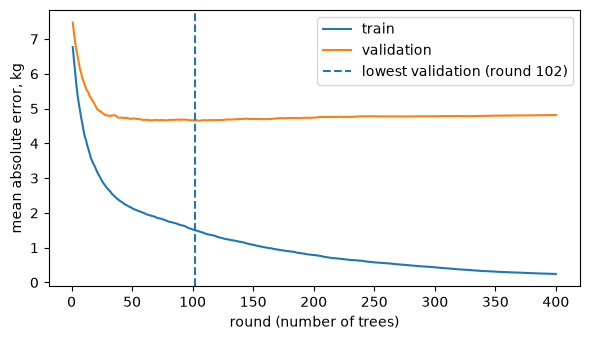

In [8]:
import matplotlib.pyplot as plt

rounds = np.arange(1, len(train_err) + 1)
plt.figure(figsize=(6, 3.5))
plt.plot(rounds, train_err, label="train")
plt.plot(rounds, val_err, label="validation")
plt.axvline(best, linestyle="--", label=f"lowest validation (round {best})")
plt.xlabel("round (number of trees)")
plt.ylabel("mean absolute error, kg")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Let the library stop early

With `n_iter_no_change=10`, scikit-learn holds out `validation_fraction=0.2` of the rows it is given and stops when that score has not improved for 10 rounds. `n_estimators_` says how many trees it kept. These models get the train and validation rows together.

**Look for:** all three stop long before 2000. `learning_rate=0.03` keeps the most trees (`89`) and `0.3` the fewest (`17`).

In [9]:
X_fit, y_fit = X[:260], harvest_rows[:260]
for lr in (0.3, 0.1, 0.03):
    m = GradientBoostingRegressor(n_estimators=2000, learning_rate=lr, max_depth=3,
                                  validation_fraction=0.2, n_iter_no_change=10, random_state=0)
    m.fit(X_fit, y_fit)
    print(f"learning_rate={lr}: trees kept n_estimators_={m.n_estimators_}  test error {mean_absolute_error(y_test, m.predict(X_test)):.2f}")

learning_rate=0.3: trees kept n_estimators_=17  test error 4.73
learning_rate=0.1: trees kept n_estimators_=29  test error 4.60
learning_rate=0.03: trees kept n_estimators_=89  test error 4.62


## 10. Outside the training range

The training rows have 8 to 14 hours of light. Here the 400-tree model is asked about brighter weeks, with temperature 23 and watering 5.

**Look for:** 14, 16, 18 and 20 hours all get the same prediction, `53.2` kg. Trees can only answer with values learned from the training rows, so past the edge the forecast goes flat.

In [10]:
print("light hours in training data %.1f to %.1f" % (light.min(), light.max()))
probe = np.array([[h, 23.0, 5.0] for h in (12, 13, 14, 16, 18, 20)])
for h, p in zip(probe[:, 0], model.predict(probe)):
    print(f"light {h:4.1f} h, temp 23, water 5 -> predicted {p:.1f} kg")

light hours in training data 8.0 to 14.0
light 12.0 h, temp 23, water 5 -> predicted 44.2 kg
light 13.0 h, temp 23, water 5 -> predicted 45.5 kg
light 14.0 h, temp 23, water 5 -> predicted 53.2 kg
light 16.0 h, temp 23, water 5 -> predicted 53.2 kg
light 18.0 h, temp 23, water 5 -> predicted 53.2 kg
light 20.0 h, temp 23, water 5 -> predicted 53.2 kg


## Now change it

Each cell below is ready to run. Change the line marked `# <- change this`, run the cell, and compare with the output above.

**Experiment 1.** Run the by-hand loop for more rounds. With `lr=0.5` and 8 rounds, every prediction should get close to the true harvest, because each round removes part of what is left. Try `rounds = 2`, then `8`, then `20`.

In [11]:
rounds = 8  # <- change this
base, sts = boost(weeks, harvest, rounds, 0.5)
p = predict(base, sts, 0.5, weeks)
print("predictions: ", np.round(p, 1).tolist())
print("true harvest:", harvest.tolist())
print("squared error:", round(float(((harvest - p) ** 2).sum()), 2))

predictions:  [30.2, 38.2, 30.2, 51.4, 43.7, 52.1, 51.7, 38.6]
true harvest: [29.0, 38.0, 30.0, 51.0, 44.0, 53.0, 52.0, 39.0]
squared error: 2.6


**Experiment 2.** Use stumps (`max_depth=1`) in the library, like you did by hand. Each tree can now ask only one question, so the model learns more slowly: the lowest validation error should come at a later round. Then try `max_depth=6`: deeper trees fit the training rows faster, and validation error should turn up sooner.

In [12]:
depth = 1  # <- change this
m = GradientBoostingRegressor(n_estimators=400, learning_rate=0.1, max_depth=depth, random_state=0).fit(X_train, y_train)
tr = [mean_absolute_error(y_train, p) for p in m.staged_predict(X_train)]
va = [mean_absolute_error(y_val, p) for p in m.staged_predict(X_val)]
b = int(np.argmin(va)) + 1
print(f"max_depth={depth}: lowest validation error at round {b}: {va[b-1]:.2f}")
print(f"after 400 rounds: train {tr[-1]:.2f}  validation {va[-1]:.2f}")

max_depth=1: lowest validation error at round 113: 4.51
after 400 rounds: train 3.07  validation 4.70


**Experiment 3.** Make early stopping more patient. With `n_iter_no_change=50` the library waits 50 rounds without improvement before it stops, so it should keep more trees. The test error may move a little either way.

In [13]:
patience = 50  # <- change this
m = GradientBoostingRegressor(n_estimators=2000, learning_rate=0.1, max_depth=3,
                              validation_fraction=0.2, n_iter_no_change=patience, random_state=0).fit(X_fit, y_fit)
print(f"n_iter_no_change={patience}: trees kept {m.n_estimators_}  test error {mean_absolute_error(y_test, m.predict(X_test)):.2f}")

n_iter_no_change=50: trees kept 90  test error 4.79

## What you should see

Tick these against the outputs above (numbers may differ slightly with other library versions):

- Training error falls at every listed round, down to about 0.25 kg at round 400.
- Validation error is lowest around round 102 (about 4.65 kg) and then rises slowly to about 4.81 kg.
- With early stopping, learning_rate=0.03 keeps the most trees (89 in our run) and 0.3 the fewest (17).
- Predictions for 14, 16, 18, 20 hours of light are all the same number (53.2 kg in our run).